In [7]:
import usf
import numpy as np

import os
usf_folders = ['/home/matt/geophysics_data/TEM/sTEM_data/2025_0227/USF_Files_dawa river/',
               '/home/matt/geophysics_data/TEM/sTEM_data/2025_0226/USF_Files_Dawa River Channel/',
            #    'E:/sTEM_data/2025_0302/USF_Files_dawa river 3/',
            #    'C:/Users/au646858/Downloads/2025_0622_profiler_sTEM53/USF_Files_profile_day_4_DD_Boren_Aliy_river/',
               '/home/matt/geophysics_data/TEM/sTEM_data/2025_0302/USF_Files_dawa river 3/'
               ]

sweeps = []
for usf_folder in usf_folders:
    usf_files = [usf_folder+f for f in os.listdir(usf_folder) if f.endswith('.usf')]
    for usf_file in usf_files:        
        sweeps += usf.Sweep.from_usf(usf_file, combine=False)
points = set([x.points for x in sweeps])

mega_sweeps = []
for pnts in points:
    mega_sweeps.append(usf.Sweep.combine_sweeps([swp for swp in sweeps if swp.points==pnts]))
lm,hm = mega_sweeps
import pandas as pd

import plotly.graph_objects as go

fig = go.Figure()

in_use_hm = np.ones_like(hm.data, dtype=bool)
in_use_lm = np.ones_like(lm.data, dtype=bool)




# Combined data
fig.add_trace(go.Scatter(x=hm.time.mean(0), y=hm.data.mean(0), mode='lines+markers', name='High Mass Mean Combined', showlegend=False))
fig.add_trace(go.Scatter(x=lm.time.mean(0), y=lm.data.mean(0), mode='lines+markers', name='Low Mass Mean Combined', showlegend=False))

fig.update_layout(
    xaxis_type="log",
    yaxis_type="log",
    xaxis_title="time [s]",
    yaxis_title="$\\frac{dB}{dt}$ \\[V / m$^2$\\]",
    margin=dict(t=30),
    dragmode='select',
)
fig

In [10]:
hm.error

array([[ 3.  ,  3.  ,  3.  , ...,  4.48,  6.79, 11.9 ],
       [ 3.  ,  3.  ,  3.  , ...,  5.03,  7.49, 10.24],
       [ 3.  ,  3.  ,  3.  , ...,  4.33,  6.49, 10.59],
       ...,
       [ 3.  ,  3.  ,  3.  , ..., 10.18, 18.44, 21.96],
       [ 3.  ,  3.  ,  3.  , ..., 11.38, 21.14, 32.52],
       [ 3.  ,  3.  ,  3.  , ...,  7.61, 13.05, 26.76]], shape=(166, 22))

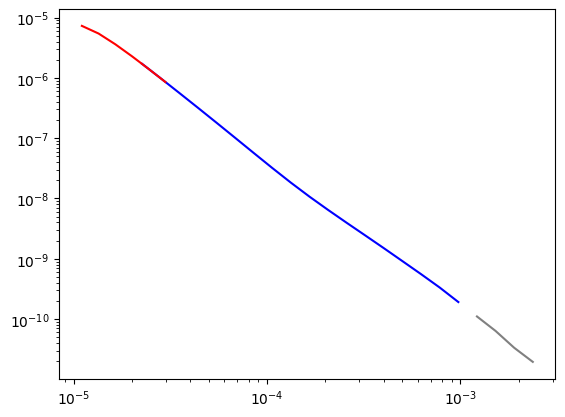

In [ ]:
import matplotlib.pyplot as plt

hm_t, hm_d = hm.time[:1], hm.data[:1]
lm_t, lm_d = lm.time[:1], lm.data[:1]




lm_inuse = np.ones_like(lm_d, dtype=bool)
hm_inuse = np.ones_like(hm_d, dtype=bool)

hm_inuse[hm_t > 1e-3] = False
lm_inuse[lm_t > 1e-3] = False


plt.figure()
plt.loglog(hm_t[hm_inuse],  hm_d[hm_inuse], '-', color='blue', label='High Mass')
plt.loglog(hm_t[hm_inuse], -hm_d[hm_inuse], '--', color='blue', label='High Mass Negative')

plt.loglog(lm_t[lm_inuse],  lm_d[lm_inuse], '-', color='red', label='Low Mass')
plt.loglog(lm_t[lm_inuse], -lm_d[lm_inuse], '--', color='red', label='Low Mass Negative')

plt.plot(hm_t[~hm_inuse],  hm_d[~hm_inuse], '-', color='gray', label='High Mass Disabled')
plt.plot(lm_t[~lm_inuse],  lm_d[~lm_inuse], '-', color='gray', label='High Mass Disabled')

plt.plot(hm_t[~hm_inuse], -hm_d[~hm_inuse], '-', color='gray', label='High Mass Disabled')
plt.plot(lm_t[~lm_inuse], -lm_d[~lm_inuse], '-', color='gray', label='High Mass Disabled')


(4, 22)


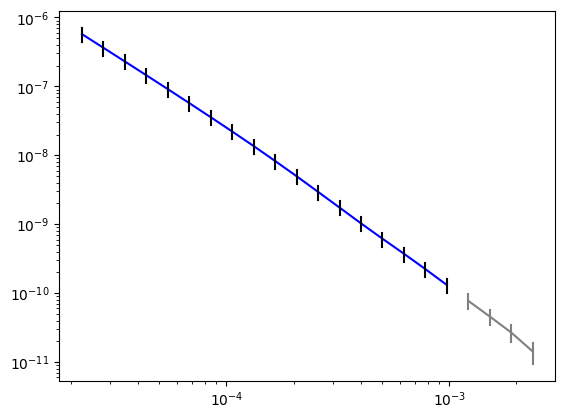

In [39]:
import matplotlib.pyplot as plt

hm_t, hm_d = hm.time[20], hm.data[20]

hm_inuse = np.ones_like(hm_d, dtype=bool)

hm.error[20] += 10.

hm_inuse[hm_t > 1e-3] = False

hm_derr = np.pad(np.vstack([hm_d*(1+0.01*hm.error[20]), hm_d*(1-0.01*hm.error[20])]), [(1,1), (0,0)], constant_values=np.nan)
hm_terr = np.vstack([hm_t, hm_t, hm_t, hm_t])

print(hm_derr.shape)
in_use_err = np.vstack([hm_inuse]*4)


plt.figure()
plt.loglog(hm_t[hm_inuse],  hm_d[hm_inuse], '-', color='blue', label='High Moment')
plt.loglog(hm_t[hm_inuse], -hm_d[hm_inuse], '--', color='blue', label='High Moment Negative')
plt.loglog(hm_terr[:, hm_inuse], hm_derr[:, hm_inuse], 'k')
plt.loglog(hm_terr[:, ~hm_inuse], hm_derr[:, ~hm_inuse], 'gray')



plt.plot(hm_t[~hm_inuse],  hm_d[~hm_inuse], '-', color='gray', label='High Moment Disabled')
plt.plot(hm_t[~hm_inuse], -hm_d[~hm_inuse], '-', color='gray', label='High Moment Disabled')

In [55]:
import plotly.graph_objects as go
import numpy as np

# Prepare data (assume hm_t, hm_d, hm_inuse, hm_derr, hm_terr are already defined as in your code)
# If not, run the previous cell to define them.

fig = go.Figure()

# In-use points (positive and negative)
# Error bars for in-use points (black)
for i in np.where(hm_inuse)[0]:
    fig.add_trace(go.Scatter(
        x=hm_terr[:, i], y=hm_derr[:, i],
        mode='lines', line=dict(color='black'), showlegend=False
    ))

# Error bars for not-in-use points (gray)
for i in np.where(~hm_inuse)[0]:
    fig.add_trace(go.Scatter(
        x=hm_terr[:, i], y=hm_derr[:, i],
        mode='lines', line=dict(color='gray'), showlegend=False
    ))

# Disabled points (gray, positive and negative)
fig.add_trace(go.Scatter(
    x=hm_t[~hm_inuse], y=hm_d[~hm_inuse],
    mode='lines', line=dict(color='gray'), name='High Mass Disabled'
))
fig.add_trace(go.Scatter(
    x=hm_t[~hm_inuse], y=-hm_d[~hm_inuse],
    mode='lines', line=dict(color='gray'), name='High Mass Disabled'
))


fig.add_trace(go.Scatter(
    x=hm_t[hm_inuse], y=hm_d[hm_inuse],
    mode='lines+markers', line=dict(color='blue'), name='High Mass'
))
fig.add_trace(go.Scatter(
    x=hm_t[hm_inuse], y=-hm_d[hm_inuse],
    mode='lines+markers', line=dict(color='blue', dash='dash'), name='High Mass Negative'
))


fig.update_layout(
    xaxis_type='log',
    yaxis_type='log',
    xaxis_title='time [s]',
    yaxis_title='dB/t [V / m2]',
)
fig.show()

In [76]:
n_traces = 10
fig = go.Figure()


n_samples = 100

for i in range(n_traces):
    x = np.linspace(-1, 1, n_samples)*4
    coef = 5*(np.random.rand(4)-0.5)  # Random coefficients for the polynomial
    zero = 3*(np.random.rand(3)-0.5)  # Random zero offset
    y = 25*np.random.randn(n_samples) + coef[0]*(x-zero[0])**3 + coef[1]*(x-zero[1])**2 + coef[2]*(x-zero[2]) + coef[3]
    fig.add_trace(go.Scatter(
        x=x, y=y,
        mode='lines+markers', 
        text=[f'gate {x_val}' for x_val in x],  # List of labels for each point
        name=f'Trace {i+1}', hoverinfo='text',  # Show only the text on hover
    ))
fig.show()

In [79]:
import dash
from dash import dcc, html, Input, Output, State
import plotly.graph_objs as go
import numpy as np

app = dash.Dash(__name__)

n_traces = 5
n_samples = 100
fig = go.Figure()
for i in range(n_traces):
    x = np.linspace(-1, 1, n_samples)*4
    y = np.random.randn(n_samples)
    fig.add_trace(go.Scatter(
        x=x, y=y,
        mode='lines+markers',
        name=f'Trace {i+1}',
        opacity=1.0
    ))

app.layout = html.Div([
    dcc.Graph(id='my-graph', figure=fig, clear_on_unhover=True)
])

# Custom clientside callback for legend hover highlighting
app.clientside_callback(
    """
    function(relayoutData, figure) {
        // relayoutData contains legendonly info on click, but not on hover.
        // Plotly does not emit a legend hover event to Dash directly.
        // This workaround dims all traces except those visible.
        if (!figure) { return window.dash_clientside.no_update; }
        let newData = figure.data.map(trace => ({...trace, opacity: 0.2}));
        if (relayoutData && relayoutData['legendonly']) {
            // If a trace is isolated, set its opacity to 1
            let idx = figure.data.findIndex(t => t.name === relayoutData['legendonly']);
            if (idx >= 0) newData[idx].opacity = 1.0;
        } else {
            // If nothing is isolated, restore all opacities
            newData = figure.data.map(trace => ({...trace, opacity: 1.0}));
        }
        return {...figure, data: newData};
    }
    """,
    Output('my-graph', 'figure'),
    Input('my-graph', 'relayoutData'),
    State('my-graph', 'figure')
)

if __name__ == '__main__':
    app.run(debug=True, port=8051)